# Simbolo aprendido con PDNO-PINN

Se aprende un simbolo $a_\theta:\mathbb{Z}^n\to\mathbb{C}$ con una MLP. Capas ocultas tienen `Tanh` + `Dropout`.

La perdida combina:

- **Trayectoria:** $\mathcal{L}_{\text{traj}} = \mathbb{E}\big[|e^{-t a_\theta(\mathbf{k})}\hat u_0(\mathbf{k}) - \hat u_{\text{ref}}(\mathbf{k},t)|^2\big]$
- **Parabolicidad:** $\mathcal{L}_{\text{par}} = \mathbb{E}\big[\max\big(0,\ |(a_\theta(\mathbf{k})+\lambda)^{-1}| - \kappa(1+|(\mathbf{k},\lambda)|^2)^{-m/2}\big)^2\big]$,
  sobre $\mathrm{Re}(\lambda)\ge 0$, $|(\mathbf{k},\lambda)|\ge\omega$.

$$\mathcal{L} = \lambda_{\text{traj}}\,\mathcal{L}_{\text{traj}} + \lambda_{\text{par}}\,\mathcal{L}_{\text{par}}$$

Como referencia se usa el calor, $a(\mathbf{k}) = |\mathbf{k}|^2$ en $\mathbb{T}^2$.

# Experimento
- **Datos:** $10^5$ muestras, particionadas en **entrenamiento (80%) y validacion (20%)**. No hay conjunto de prueba.
- **$\kappa$ como hiperparametro**
- **Arquitectura:** barrido de $\{2,3,4\}$ capas ocultas $\times$ $\{32,64,128\}$ neuronas.
- **Regularizacion:** dropout $0.2$ tras cada activacion oculta, y **early stopping** sobre la
  perdida total de validacion.

In [ ]:
import sys
sys.path.insert(0, "../src")  # ruta para las clases

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from parabolic_symbol.ParabolicityVerifier import ParabolicityVerifier
from parabolic_symbol.symbols.heat import HeatSymbol
from parabolic_symbol.symbols.mlp_symbol import MLPSymbol, default_device
from parabolic_symbol.training import (
    TrainingConfig,
    best_run,
    k_grid,
    make_trajectory_data,
    phase_grid,
    run_sweep,
    split_trajectory_data,
    sweep_table,
    symbol_report,
    trajectory_report,
)

np.set_printoptions(precision=4, suppress=True)

device = default_device()
dtype = torch.float32 if device.type == "cuda" else torch.float64
print(f"device = {device}  |  dtype = {dtype}")

## 1. Datos de referencia

$\hat u_{\text{ref}}(\mathbf{k},t) = e^{-t|\mathbf{k}|^2}\hat u_0(\mathbf{k})$, con $|k_i|\le k_{\max}$.
El tiempo se muestrea log-uniforme.

In [2]:
n = 2
k_max = 8
reference = HeatSymbol(n=n)

data = make_trajectory_data(
    reference, k_max=k_max, n_samples=100_000, t_min=1e-3, t_max=1.0, seed=0
)
train_data, val_data = split_trajectory_data(data, val_fraction=0.2, seed=0)

print(f"entrenamiento: {train_data['k'].shape[0]:,} muestras")
print(f"validacion:    {val_data['k'].shape[0]:,} muestras")

entrenamiento: 80,000 muestras
validacion:    20,000 muestras


## 2. Malla de $\kappa$

Se estima $\hat\kappa$ del simbolo de referencia con el verificador y se construye una malla alrededor.
Valores por debajo de $\hat\kappa$ son cotas mas exigentes que las que cumple el propio calor sobre esta rejilla.

In [3]:
omega = 1.0
k_values = list(k_grid(n, k_max))
lam_values = [complex(re, im) for re in (0, 1, 5, 10, 25, 50) for im in (-50, -10, -2, 0, 2, 10, 50)]

kappa_ref = ParabolicityVerifier(reference).estimate_kappa(k_values, lam_values, omega=omega)
kappas = [round(factor * kappa_ref, 3) for factor in (0.75, 1.0, 1.25, 1.5, 2.0)]

print(f"kappa_hat referencia = {kappa_ref:.4f}")
print(f"malla de kappa       = {kappas}")

kappa_hat referencia = 2.0000
malla de kappa       = [1.5, 2.0, 2.5, 3.0, 4.0]


## 3. Barrido de hiperparametros

Ejes: $5$ valores de $\\kappa$ $\\times$ $3$ profundidades $\\times$ $3$ anchos $\\times$ ubicacion del
dropout $\\times$ $2$ weight decays $=$ **150 entrenamientos** (~3.2 h).

- **Dropout:** tasa **fija** de $0.2$; lo que se compara es *donde* se aplica, `none` frente a `middle`
  (capas ocultas interiores, excluyendo la primera y la ultima). Con $2$ capas ocultas `middle` no deja
  ninguna capa, asi que equivale a `none` y esa corrida no se repite.
- **Weight decay:** $\\{0,\\ 10^{-4}\\}$, uniforme sobre las `Linear` ocultas interiores (quedan fuera la
  `Linear` de entrada y la de salida). Desacoplado, via AdamW.

Cada corrida se marca como **cumple** si el peor ratio
$|(a_\\theta+\\lambda)^{-1}| \\big/ \\kappa(1+|(\\mathbf{k},\\lambda)|^2)^{-m/2}$
sobre la rejilla fija de comprobacion es $\\le 1$. Esa rejilla es independiente de los puntos
muestreados en la perdida, asi que la decision no esta contaminada por el entrenamiento.

In [4]:
check_phase = phase_grid(n, k_max, lam_values, device=device, dtype=dtype)

base_config = TrainingConfig(
    epochs=300,
    batch_size=1024,
    lr=1e-3,
    lr_final=1e-5,
    omega=omega,
    lambda_trajectory=1.0,
    lambda_parabolicity=1.0,
    k_max=k_max,
    lam_min=1e-2,
    lam_max=1e2,
    grad_clip=1.0,
    patience=30,        # early stopping
    n_phase_eval=8192,  # puntos (k, lambda) fijos para las metricas por epoca
    log_every=0,        # el barrido ya imprime dos lineas por corrida
    seed=0,
)

# La tasa de dropout es fija (0.2); el eje que se barre es DONDE se aplica.
# "middle" = capas ocultas interiores, sin la primera ni la ultima. Con 2 capas
# ocultas eso no deja ninguna, asi que coincide con "none" y run_sweep no repite
# esa corrida: profundidad 2 aporta la mitad de combinaciones que 3 y 4.
runs = run_sweep(
    train_data,
    val_data,
    n=n,
    m=2.0,
    kappas=kappas,
    depths=[2, 3, 4],
    widths=[32, 64, 128],
    base_config=base_config,
    check_phase=check_phase,
    dropout=0.2,
    dropout_layers=["none", "middle"],
    weight_decays=[0.0, 1e-4],
    input_scale=k_max,
    output_scale=k_max**2,
    device=device,
    dtype=dtype,
)

kappa= 1.500 capas=2 ancho= 32 | dropout OFF | wd=0e+00 | NO cumple max_ratio(rejilla)=1.145
    val: total=2.929e-04 traj=2.474e-04 par=4.558e-05 rel_l2=0.0281 max_ratio=1.286 viol= 1.28% | epocas 300 (mejor 299) |  81.8s
kappa= 1.500 capas=2 ancho= 32 | dropout OFF | wd=1e-04 | NO cumple max_ratio(rejilla)=1.145
    val: total=2.942e-04 traj=2.484e-04 par=4.578e-05 rel_l2=0.0281 max_ratio=1.286 viol= 1.27% | epocas 300 (mejor 299) |  84.6s
kappa= 1.500 capas=2 ancho= 64 | dropout OFF | wd=0e+00 | NO cumple max_ratio(rejilla)=1.141
    val: total=1.747e-04 traj=1.389e-04 par=3.577e-05 rel_l2=0.0210 max_ratio=1.261 viol= 1.05% | epocas 300 (mejor 298) |  87.2s
kappa= 1.500 capas=2 ancho= 64 | dropout OFF | wd=1e-04 | NO cumple max_ratio(rejilla)=1.143
    val: total=1.709e-04 traj=1.362e-04 par=3.469e-05 rel_l2=0.0208 max_ratio=1.256 viol= 1.08% | epocas 300 (mejor 298) |  85.5s
kappa= 1.500 capas=2 ancho=128 | dropout OFF | wd=0e+00 | NO cumple max_ratio(rejilla)=1.125
    val: total=

## 4. Resultados del barrido

In [5]:
table = sweep_table(runs)

# Metricas de validacion en la mejor epoca (las que se usan para decidir):
#   val_total          = lambda_traj * trayectoria + lambda_par * parabolicidad
#   val_trajectory     = E[|exp(-t a) u0 - u_ref|^2]
#   val_parabolicity   = hinge^2 sobre la cota de la Def. 2.3
#   val_rel_l2         = error relativo L2 de la trayectoria
#   val_par_max_ratio  = peor ratio resolvente/cota en los puntos de validacion
#   val_par_violation  = fraccion de esos puntos con ratio > 1
VAL_COLS = ["val_total", "val_trajectory", "val_parabolicity",
            "val_rel_l2", "val_par_max_ratio", "val_par_violation"]
COLS = ["kappa", "capas", "ancho", "dropout", "weight_decay",
        "cumple", "max_ratio", *VAL_COLS, "mejor_epoca", "epocas"]

table[COLS].sort_values(["kappa", "val_rel_l2"]).reset_index(drop=True)

,kappa,capas,ancho,dropout,weight_decay,cumple,max_ratio,val_total,val_trajectory,val_parabolicity,val_rel_l2,val_par_max_ratio,val_par_violation,mejor_epoca,epocas
0,1.5,3,128,OFF,0.0000,False,1.120310,0.000092,0.000060,0.000032,0.013839,1.225591,0.011122,298,300
1,1.5,4,64,OFF,0.0001,False,1.120424,0.000093,0.000065,0.000028,0.014357,1.229225,0.010389,296,300
2,1.5,4,64,OFF,0.0000,False,1.119435,0.000093,0.000065,0.000028,0.014410,1.226234,0.010389,296,300
3,1.5,2,128,OFF,0.0000,False,1.125447,0.000093,0.000066,0.000026,0.014521,1.225007,0.010633,295,300
4,1.5,3,128,OFF,0.0001,False,1.116189,0.000093,0.000067,0.000026,0.014571,1.215528,0.010633,267,297
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,4.0,4,64,"ON p=0.2 capas[1,2]",0.0001,True,0.750070,0.001080,0.001080,0.000000,0.058685,0.578584,0.000000,115,145
146,4.0,4,32,"ON p=0.2 capas[1,2]",0.0001,True,0.685227,0.001247,0.001247,0.000000,0.063055,0.673785,0.000000,48,78
147,4.0,3,128,ON p=0.2 capas[1],0.0000,True,0.649179,0.001293,0.001293,0.000000,0.064205,0.642640,0.000000,43,73
148,4.0,3,64,ON p=0.2 capas[1],0.0000,False,1.080760,0.001486,0.001481,0.000005,0.068725,1.110927,0.000367,27,57


In [6]:
# Por kappa, y por configuracion de regularizacion (dropout / weight decay).
resumen = table.groupby("kappa").agg(
    cumplen=("cumple", "sum"),
    corridas=("cumple", "count"),
    mejor_max_ratio=("max_ratio", "min"),
    mejor_val_rel_l2=("val_rel_l2", "min"),
    mejor_val_total=("val_total", "min"),
)
display(resumen)

for eje in ("dropout", "weight_decay"):
    if table[eje].nunique() > 1:
        display(
            table[table["cumple"]].groupby(eje).agg(
                cumplen=("cumple", "size"),
                kappa_min=("kappa", "min"),
                mejor_val_rel_l2=("val_rel_l2", "min"),
                mejor_val_total=("val_total", "min"),
                peor_ratio=("val_par_max_ratio", "min"),
            )
        )

,cumplen,corridas,mejor_max_ratio,mejor_val_rel_l2,mejor_val_total
kappa,,,,,
1.5,0,30,1.116189,0.013839,0.000092
2.0,14,30,0.933141,0.005613,0.000013
2.5,22,30,0.807694,0.002621,0.000002
3.0,29,30,0.672313,0.003157,0.000003
4.0,29,30,0.494603,0.003127,0.000003


,cumplen,kappa_min,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,,
OFF,68,2.0,0.002621,0.000002,0.561537
"ON p=0.2 capas[1,2]",13,2.5,0.017173,0.000092,0.538633
ON p=0.2 capas[1],13,2.5,0.022672,0.000161,0.596932


,cumplen,kappa_min,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,,
0.0000,47,2.0,0.003157,0.000003,0.565140
0.0001,47,2.0,0.002621,0.000002,0.538633


### Seleccion: el $\kappa$ mas chico que se logra satisfacer

Entre las corridas que cumplen se toma el $\kappa$ minimo; a igualdad de $\kappa$, la de mejor
error relativo de validacion.

In [7]:
best = best_run(runs)
if best is None:
    raise RuntimeError("ningun kappa de la malla se logro satisfacer; ampliar la malla hacia arriba")

symbol = best.symbol
print(f"kappa minimo satisfecho = {best.kappa:.4f}   (kappa_hat referencia = {kappa_ref:.4f})")
print(f"arquitectura elegida    = {best.n_layers} capas x {best.width} neuronas")
print(f"dropout                 = {best.dropout_desc}")
print(f"weight decay            = {best.weight_decay:g}  (Linear ocultas interiores)")
print(f"early stopping          = mejor epoca {best.best_epoch} de {best.epochs_run} corridas")
print(f"max ratio en la rejilla = {best.max_ratio:.4f}  (<= 1 => la cota se cumple)")
print()
print("metricas de validacion en la mejor epoca:")
print(f"  total             = {best.val_total:.4e}")
print(f"  trayectoria       = {best.val_trajectory:.4e}")
print(f"  parabolicidad     = {best.val_parabolicity:.4e}   (0 => ningun punto viola la cota)")
print(f"  rel_l2            = {best.val_rel_l2:.4f}")
print(f"  peor ratio        = {best.val_par_max_ratio:.4f}")
print(f"  puntos con >1     = {100 * best.val_par_violation:.2f}%")

kappa minimo satisfecho = 2.0000   (kappa_hat referencia = 2.0000)
arquitectura elegida    = 2 capas x 128 neuronas
dropout                 = OFF
weight decay            = 0  (Linear ocultas interiores)
early stopping          = mejor epoca 289 de 300 corridas
max ratio en la rejilla = 0.9503  (<= 1 => la cota se cumple)

metricas de validacion en la mejor epoca:
  total             = 1.3046e-05
  trayectoria       = 9.8798e-06
  parabolicidad     = 3.1662e-06   (0 => ningun punto viola la cota)
  rel_l2            = 0.0056
  peor ratio        = 1.0747
  puntos con >1     = 0.21%


### Metricas del modelo seleccionado

Dos reportes distintos, porque son dos cosas distintas:

- **Trayectoria** $\hat u(\mathbf{k},t) = e^{-t a_\theta(\mathbf{k})}\hat u_0(\mathbf{k})$: es lo que la
  perdida optimiza. El residuo es complejo, asi que el error por muestra es el modulo
  $|\hat u_{\text{pred}} - \hat u_{\text{ref}}|$ y de ahi salen RMSE, MAE y $R^2$.
- **Simbolo** $a_\theta(\mathbf{k})$ frente a $|\mathbf{k}|^2$: es la cantidad que acota la teoria. La
  perdida solo lo ve a traves de $e^{-t a_\theta}$, que para $|\mathbf{k}|$ grande es practicamente $0$ y
  deja de informar, por eso el error del simbolo puede ser mucho peor que el de la trayectoria.

La comparacion entrenamiento / validacion es la que dice si la regularizacion esta haciendo algo:
un hueco grande entre las dos columnas es sobreajuste.

In [ ]:
traj = {"entrenamiento": trajectory_report(symbol, train_data),
        "validacion": trajectory_report(symbol, val_data)}
n_muestras = {split: int(rep.pop("n")) for split, rep in traj.items()}

print("TRAYECTORIA  -- residuo complejo |u_pred - u_ref|")
print(f"  muestras: {n_muestras['entrenamiento']:,} entrenamiento / {n_muestras['validacion']:,} validacion")
display(pd.DataFrame(traj))

sym = symbol_report(symbol, reference, k_values)
print(f"SIMBOLO  -- a_theta(k) vs |k|^2 sobre {int(sym.pop('n')):,} puntos de la rejilla |k_i| <= k_max")
display(pd.DataFrame({"valor": sym}))

print("PARABOLICIDAD")
print(f"  kappa usada           = {best.kappa:.4f}")
print(f"  peor ratio (rejilla)  = {best.max_ratio:.4f}   (<= 1 => la cota se cumple)")
print(f"  hinge^2 de validacion = {best.val_parabolicity:.4e}")

## 5. Curvas de entrenamiento

Las metricas de ambos conjuntos se calculan al final de cada epoca **en modo eval** (dropout apagado),
asi las dos curvas son directamente comparables. La linea punteada marca la epoca cuyos pesos
restauro el early stopping.

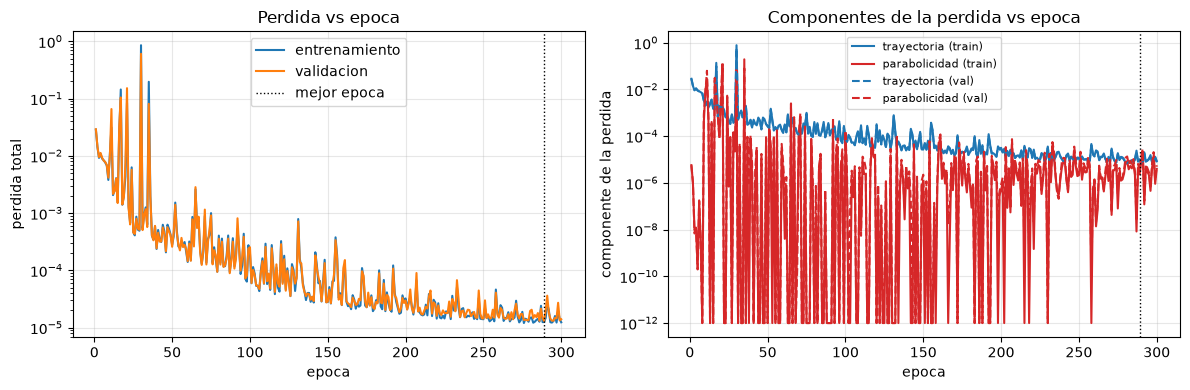

In [8]:
history = best.result.history
epochs = np.arange(1, len(history["train"]["total"]) + 1)
floor = 1e-12  # recorte para la escala logaritmica

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].semilogy(epochs, history["train"]["total"], label="entrenamiento")
axes[0].semilogy(epochs, history["val"]["total"], label="validacion")
axes[0].axvline(best.best_epoch, color="k", ls=":", lw=1, label="mejor epoca")
axes[0].set_xlabel("epoca")
axes[0].set_ylabel("perdida total")
axes[0].set_title("Perdida vs epoca")
axes[0].legend()
axes[0].grid(alpha=0.3)

for split, style in (("train", "-"), ("val", "--")):
    axes[1].semilogy(epochs, np.maximum(history[split]["trajectory"], floor), style,
                     color="C0", label=f"trayectoria ({split})")
    axes[1].semilogy(epochs, np.maximum(history[split]["parabolicity"], floor), style,
                     color="C3", label=f"parabolicidad ({split})")
axes[1].axvline(best.best_epoch, color="k", ls=":", lw=1)
axes[1].set_xlabel("epoca")
axes[1].set_ylabel("componente de la perdida")
axes[1].set_title("Componentes de la perdida vs epoca")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

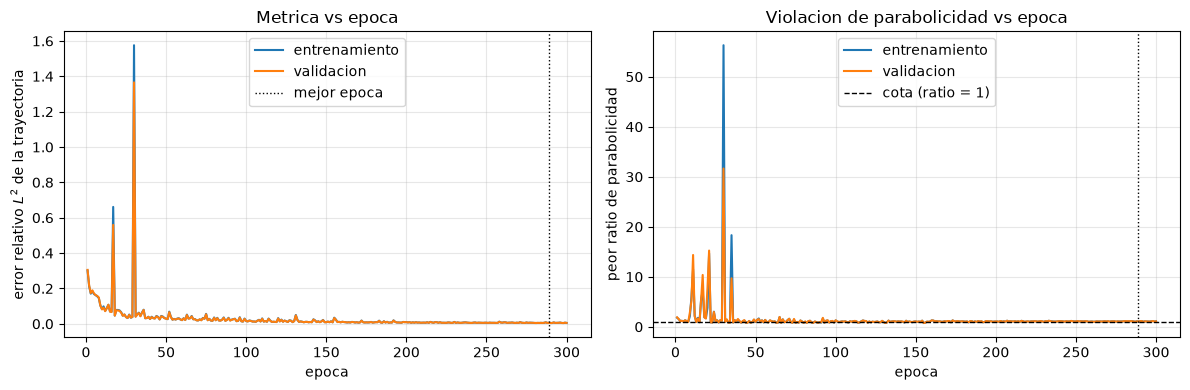

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train"]["rel_l2"], label="entrenamiento")
axes[0].plot(epochs, history["val"]["rel_l2"], label="validacion")
axes[0].axvline(best.best_epoch, color="k", ls=":", lw=1, label="mejor epoca")
axes[0].set_xlabel("epoca")
axes[0].set_ylabel(r"error relativo $L^2$ de la trayectoria")
axes[0].set_title("Metrica vs epoca")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train"]["par_max_ratio"], label="entrenamiento")
axes[1].plot(epochs, history["val"]["par_max_ratio"], label="validacion")
axes[1].axhline(1.0, color="k", ls="--", lw=1, label="cota (ratio = 1)")
axes[1].axvline(best.best_epoch, color="k", ls=":", lw=1)
axes[1].set_xlabel("epoca")
axes[1].set_ylabel("peor ratio de parabolicidad")
axes[1].set_title("Violacion de parabolicidad vs epoca")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

La perdida de parabolicidad vale exactamente $0$ en las epocas donde ningun punto muestreado viola la cota
(en la grafica se recorta a $10^{-12}$ para la escala logaritmica).

## 6. Simbolo aprendido vs. referencia

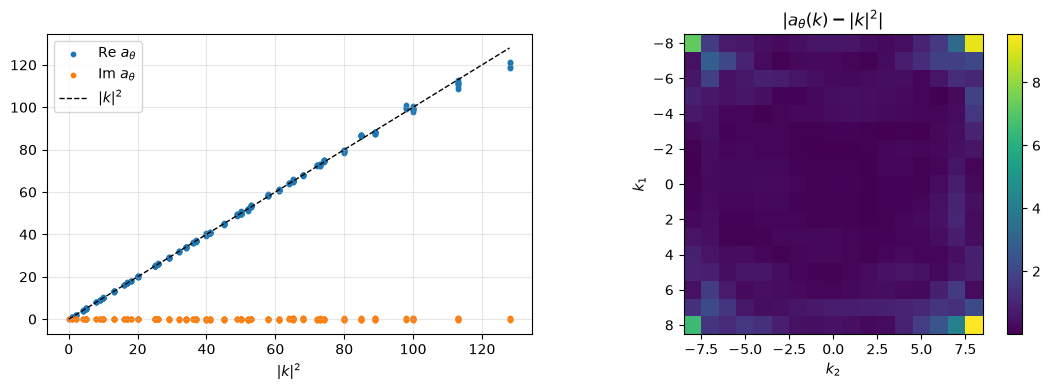

error relativo medio = 0.012, maximo = 0.089


In [10]:
k_arr = np.array(k_values)
a_true = np.array([reference(k)[0, 0] for k in k_values])
a_learn = symbol.evaluate_batch(k_arr)   # un solo forward por lotes
norm_k2 = np.sum(k_arr**2, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(norm_k2, a_learn.real, s=10, label=r"Re $a_\theta$")
axes[0].scatter(norm_k2, a_learn.imag, s=10, label=r"Im $a_\theta$")
axes[0].plot(np.sort(norm_k2), np.sort(norm_k2), "k--", lw=1, label=r"$|k|^2$")
axes[0].set_xlabel(r"$|k|^2$")
axes[0].legend()
axes[0].grid(alpha=0.3)

im = axes[1].imshow(
    np.abs(a_learn - a_true).reshape(2 * k_max + 1, 2 * k_max + 1),
    extent=[-k_max - 0.5, k_max + 0.5, k_max + 0.5, -k_max - 0.5],
)
axes[1].set_title(r"$|a_\theta(k) - |k|^2|$")
axes[1].set_xlabel(r"$k_2$")
axes[1].set_ylabel(r"$k_1$")
fig.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()

rel = np.abs(a_learn - a_true) / np.maximum(norm_k2, 1)
print(f"error relativo medio = {rel.mean():.3f}, maximo = {rel.max():.3f}")

Para $|\mathbf{k}|$ grande $e^{-t|\mathbf{k}|^2}\approx 0$ en casi todo el rango de $t$, asi que la perdida de
trayectoria da poca informacion alli y el error es mayor.

## 7. Verificacion con `ParabolicityVerifier`

`MLPSymbol` hereda de `Symbol`, asi que se pasa al verificador sin cambios.

In [11]:
verifier = ParabolicityVerifier(symbol)

kappa_learned = verifier.estimate_kappa(k_values, lam_values, omega=omega)
results = verifier.check_region(k_values, lam_values, omega=omega, kappa=best.kappa)

print(f"{symbol!r}")
print(f"kappa_hat del simbolo aprendido = {kappa_learned:.4f}  (kappa usada = {best.kappa:.4f})")
print(f"Se cumple en toda la rejilla ({len(results)} puntos): {all(r.holds for r in results)}")
print(f"max ratio = {max(r.ratio for r in results):.4f}")

MLPSymbol(hidden=(128, 128), sin dropout)(n=2, m=2.0, rho=3, dim=1)
kappa_hat del simbolo aprendido = 1.9007  (kappa usada = 2.0000)
Se cumple en toda la rejilla (12137 puntos): True
max ratio = 0.9503


In [12]:
worst = sorted(results, key=lambda r: -r.ratio)[:5]
for r in worst:
    print(f"k={r.k}, lambda={r.lam}, ratio={r.ratio:.4f}")

k=[1 0], lambda=0j, ratio=0.9503
k=[-1  0], lambda=0j, ratio=0.9381
k=[ 0 -1], lambda=0j, ratio=0.9301
k=[0 1], lambda=0j, ratio=0.9221
k=[0 0], lambda=(1+0j), ratio=0.9186


## 8. Fuera de la ventana de entrenamiento

La salida de la red (Tanh + capa lineal) esta acotada, asi que $a_\theta$ no puede crecer como $|\mathbf{k}|^m$
para todo $\mathbf{k}\in\mathbb{Z}^n$. La parabolicidad solo puede garantizarse en la ventana muestreada;
fuera de ella se espera que la cota falle.

In [13]:
# Ratio de parabolicidad sobre k_np x lam_values, con un solo forward por lotes.
def ratios_on_grid(symbol, k_np, lam_values, omega, kappa):
    kk = np.repeat(k_np, len(lam_values), axis=0)
    ll = np.tile(np.asarray(lam_values, dtype=complex), len(k_np))
    a = symbol.evaluate_batch(kk)
    norm = np.sqrt(np.sum(kk**2, axis=1) + np.abs(ll) ** (2.0 / symbol.m))
    keep = (ll.real >= 0) & (norm >= omega)
    kk, ll, norm, a = kk[keep], ll[keep], norm[keep], a[keep]
    bound = kappa * (1.0 + norm**2) ** (-symbol.m / 2.0)
    return kk, (1.0 / np.abs(a + ll)) / bound


k_far = k_grid(n, 3 * k_max)
kk_far, ratio_far = ratios_on_grid(symbol, k_far, lam_values, omega, best.kappa)
fails = ratio_far > 1.0

print(f"|k_i| <= {3 * k_max}: se cumple en todos los puntos: {not fails.any()}")
print(f"puntos que fallan: {fails.sum()} de {ratio_far.size}")
if fails.any():
    print(f"menor max|k_i| con falla: {int(np.abs(kk_far[fails]).max(axis=1).min())}")

|k_i| <= 24: se cumple en todos los puntos: False
puntos que fallan: 67386 de 100841
menor max|k_i| con falla: 11
